First 5 Rows
   person_age person_gender person_education  person_income  person_emp_exp  \
0        22.0        female           Master        71948.0               0   
1        21.0        female      High School        12282.0               0   
2        25.0        female      High School        12438.0               3   
3        23.0        female         Bachelor        79753.0               0   
4        24.0          male           Master        66135.0               1   

  person_home_ownership  loan_amnt loan_intent  loan_int_rate  \
0                  RENT    35000.0    PERSONAL          16.02   
1                   OWN     1000.0   EDUCATION          11.14   
2              MORTGAGE     5500.0     MEDICAL          12.87   
3                  RENT    35000.0     MEDICAL          15.23   
4                  RENT    35000.0     MEDICAL          14.27   

   loan_percent_income  cb_person_cred_hist_length  credit_score  \
0                 0.49                         3.0   

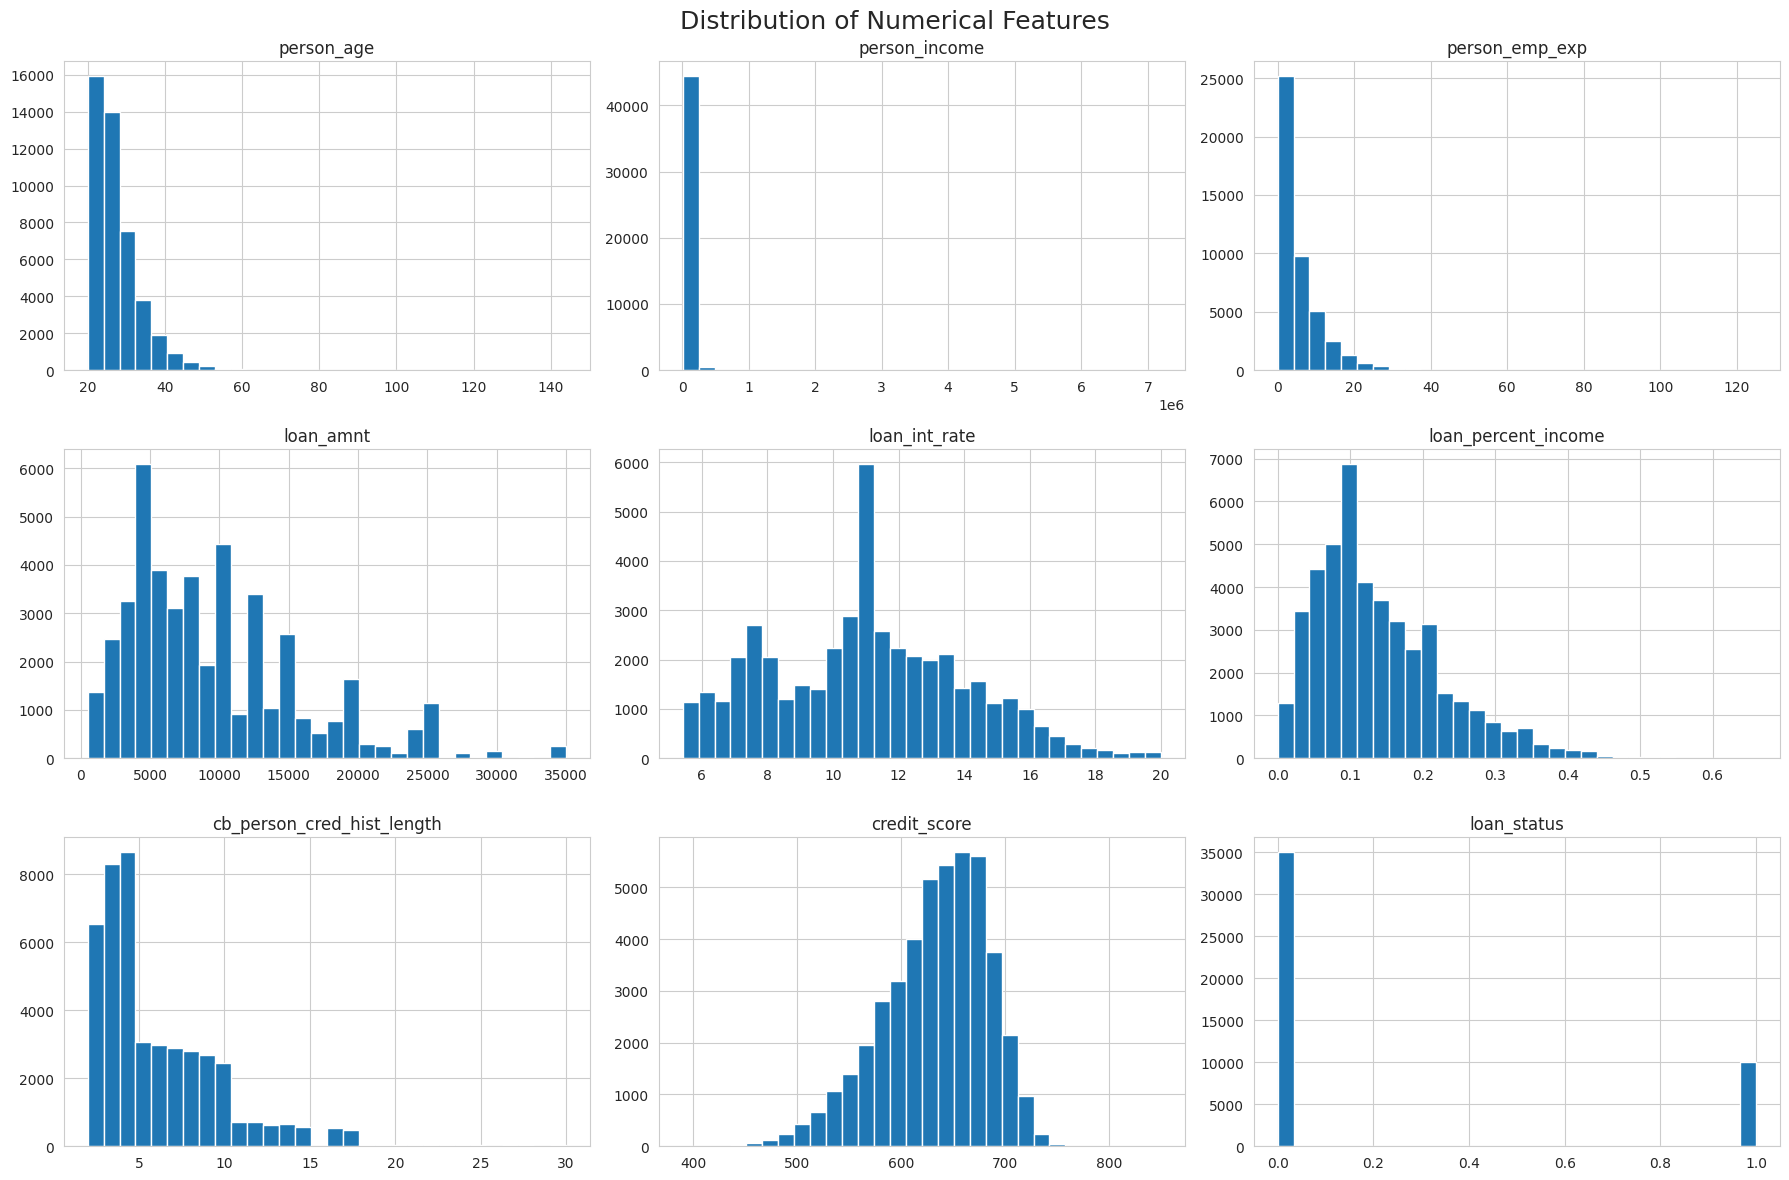

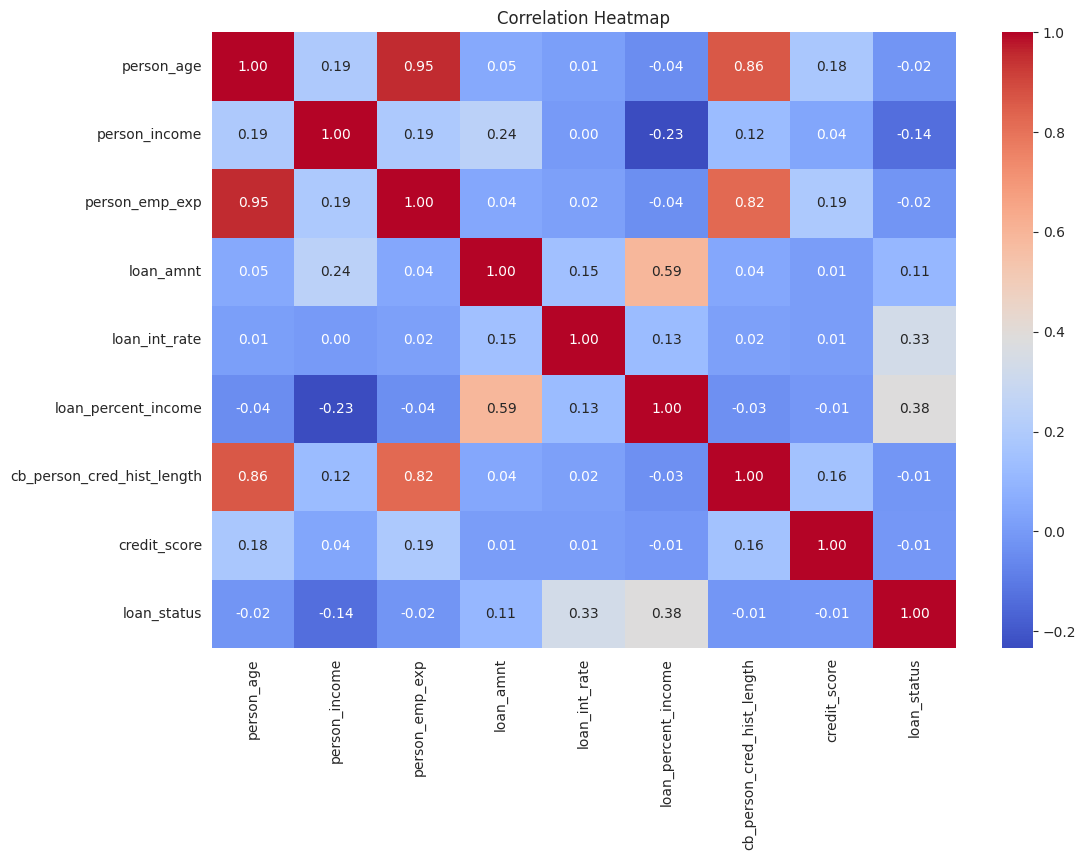

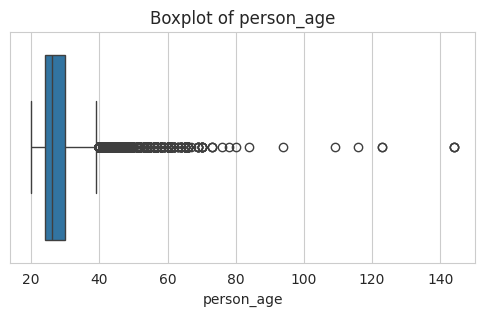

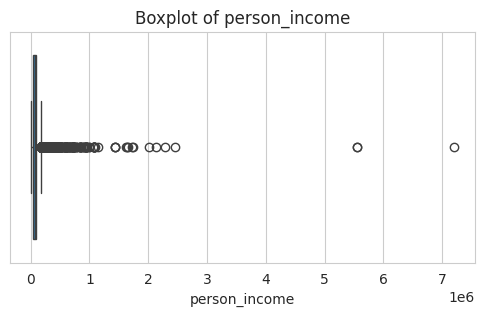

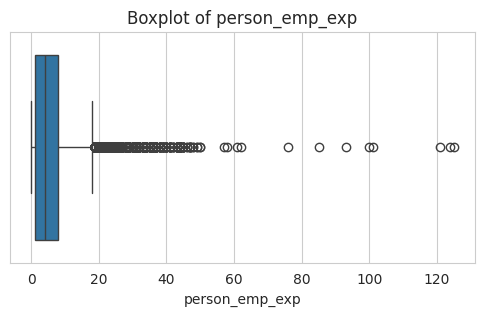

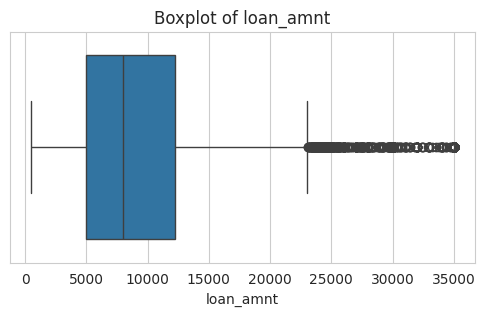

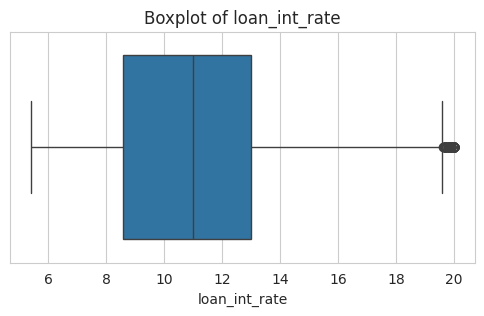

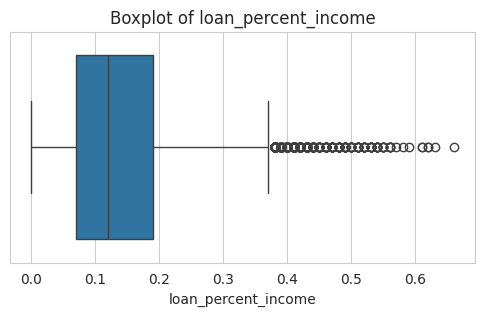

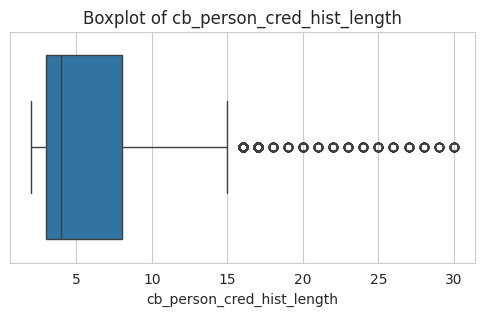

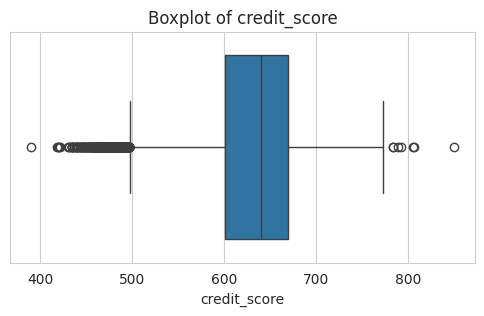

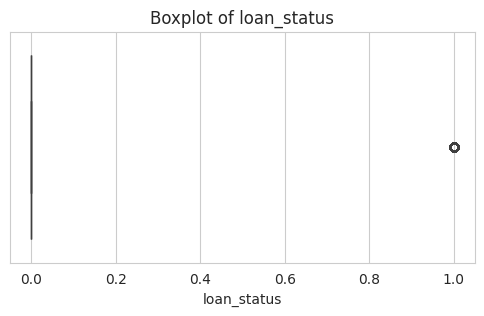

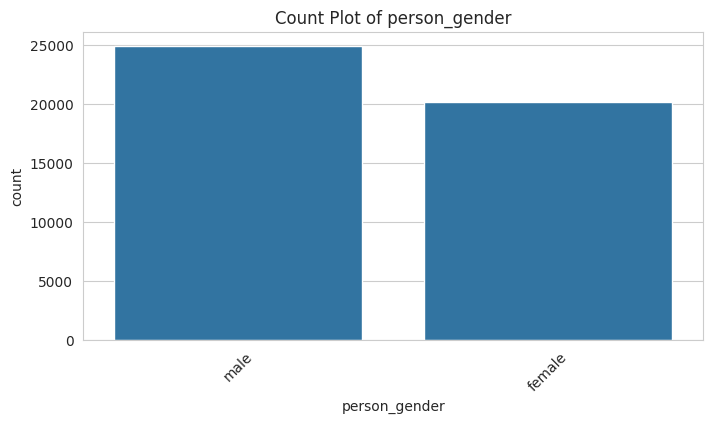

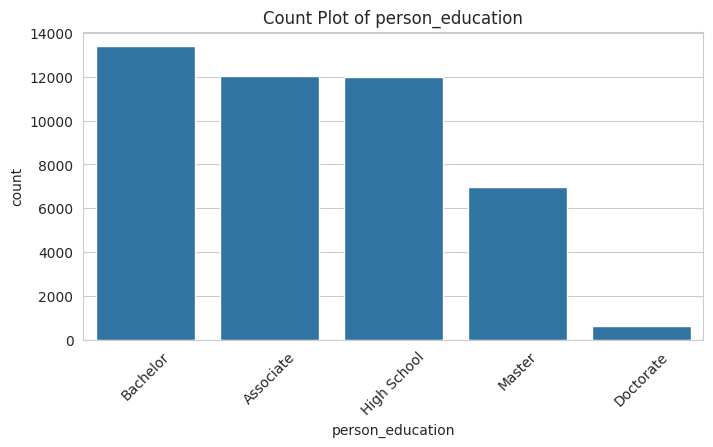

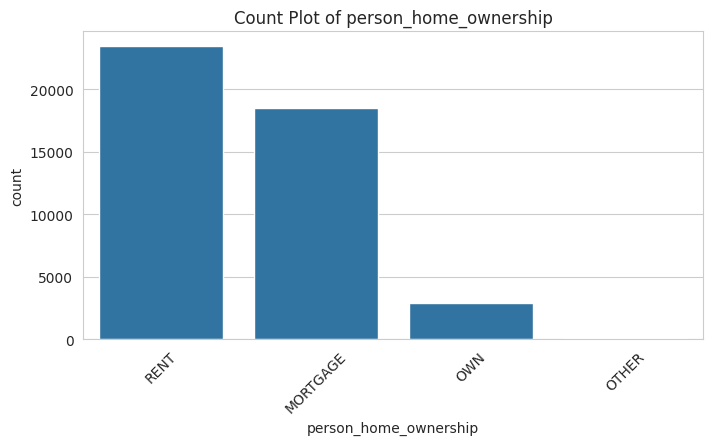

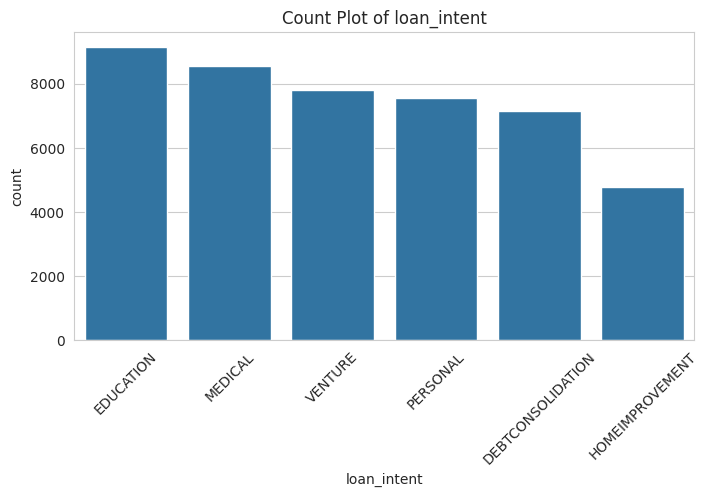

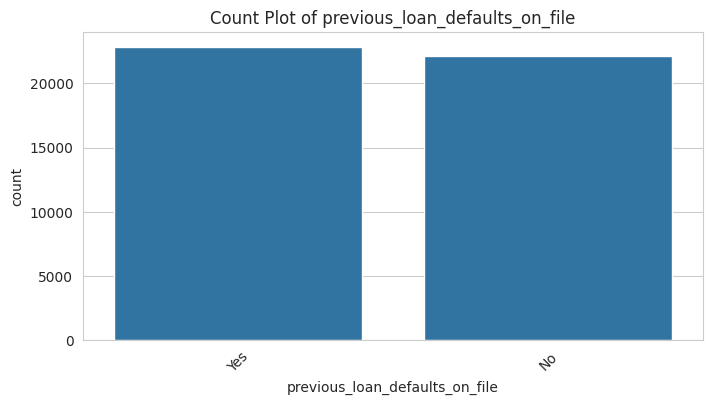

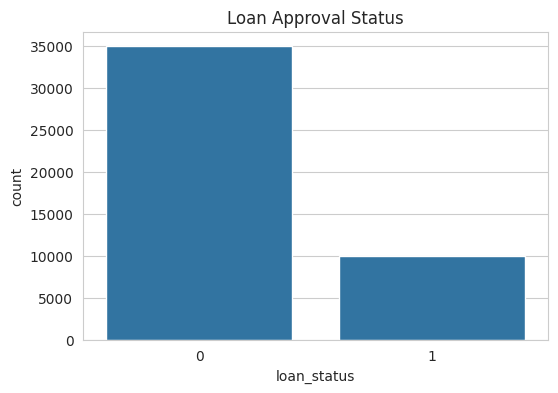


Loan Status Percentage
loan_status
0    77.78
1    22.22
Name: proportion, dtype: float64

EDA Completed Successfully!


In [1]:
# ==========================================
# Import Required Libraries
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display Settings
pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")

# ==========================================
# Load Dataset
# ==========================================
df = pd.read_csv("/kaggle/input/datasets/taweilo/loan-approval-classification-data/loan_data.csv")

# ==========================================
# Basic Information
# ==========================================
print("="*60)
print("First 5 Rows")
print("="*60)
print(df.head())

print("\n" + "="*60)
print("Last 5 Rows")
print("="*60)
print(df.tail())

print("\n" + "="*60)
print("Dataset Shape")
print("="*60)
print(df.shape)

print("\n" + "="*60)
print("Column Names")
print("="*60)
print(df.columns.tolist())

print("\n" + "="*60)
print("Dataset Information")
print("="*60)
print(df.info())

print("\n" + "="*60)
print("Data Types")
print("="*60)
print(df.dtypes)

# ==========================================
# Missing Values
# ==========================================
print("\n" + "="*60)
print("Missing Values")
print("="*60)
print(df.isnull().sum())

# ==========================================
# Duplicate Values
# ==========================================
print("\n" + "="*60)
print("Duplicate Rows")
print("="*60)
print(df.duplicated().sum())

# ==========================================
# Statistical Summary
# ==========================================
print("\n" + "="*60)
print("Numerical Statistics")
print("="*60)
print(df.describe())

print("\n" + "="*60)
print("Categorical Statistics")
print("="*60)
print(df.describe(include='object'))

# ==========================================
# Unique Values
# ==========================================
print("\n" + "="*60)
print("Unique Values in Each Column")
print("="*60)
print(df.nunique())

# ==========================================
# Target Variable Distribution
# ==========================================
print("\nLoan Status Distribution")
print(df["loan_status"].value_counts())

# ==========================================
# Numerical Columns
# ==========================================
num_cols = df.select_dtypes(include=np.number).columns

# Histograms
df[num_cols].hist(figsize=(18,12), bins=30)
plt.suptitle("Distribution of Numerical Features", fontsize=18)
plt.tight_layout()
plt.show()

# ==========================================
# Correlation Heatmap
# ==========================================
plt.figure(figsize=(12,8))
sns.heatmap(df[num_cols].corr(),
            annot=True,
            cmap="coolwarm",
            fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

# ==========================================
# Boxplots (Outlier Detection)
# ==========================================
for col in num_cols:
    plt.figure(figsize=(6,3))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

# ==========================================
# Categorical Columns
# ==========================================
cat_cols = df.select_dtypes(include="object").columns

for col in cat_cols:
    plt.figure(figsize=(8,4))
    sns.countplot(data=df, x=col, order=df[col].value_counts().index)
    plt.title(f"Count Plot of {col}")
    plt.xticks(rotation=45)
    plt.show()

# ==========================================
# Loan Status Count Plot
# ==========================================
plt.figure(figsize=(6,4))
sns.countplot(data=df, x="loan_status")
plt.title("Loan Approval Status")
plt.show()

# ==========================================
# Target Percentage
# ==========================================
print("\nLoan Status Percentage")
print((df["loan_status"].value_counts(normalize=True)*100).round(2))

print("\nEDA Completed Successfully!")

In [3]:
# ==========================================
# DATA PREPROCESSING (Single Cell)
# ==========================================

import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Create a copy of dataset
data = df.copy()

# ------------------------------------------
# Remove Duplicate Rows
# ------------------------------------------
print("Duplicate Rows Before:", data.duplicated().sum())
data = data.drop_duplicates()
print("Duplicate Rows After :", data.duplicated().sum())

# ------------------------------------------
# Separate Numerical and Categorical Columns
# ------------------------------------------
num_cols = data.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = data.select_dtypes(include=['object']).columns.tolist()

# Remove target column from numerical columns (if present)
if 'loan_status' in num_cols:
    num_cols.remove('loan_status')

# ------------------------------------------
# Handle Missing Values
# ------------------------------------------
for col in num_cols:
    data[col] = data[col].fillna(data[col].median())

for col in cat_cols:
    data[col] = data[col].fillna(data[col].mode()[0])

print("\nMissing Values:")
print(data.isnull().sum())

# ------------------------------------------
# Encode Categorical Features
# ------------------------------------------
label_encoders = {}

for col in cat_cols:
    le = LabelEncoder()
    data[col] = le.fit_transform(data[col].astype(str))
    label_encoders[col] = le

print("\nCategorical Features Encoded Successfully!")

# ------------------------------------------
# Separate Features and Target
# ------------------------------------------
X = data.drop('loan_status', axis=1)
y = data['loan_status']

# ------------------------------------------
# Feature Scaling (Required for SVC)
# ------------------------------------------
scaler = StandardScaler()
X = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

# ------------------------------------------
# Final Output
# ------------------------------------------
print("\nPreprocessing Completed Successfully!")
print("Feature Matrix Shape :", X.shape)
print("Target Shape         :", y.shape)

print("\nFirst 5 Rows of Processed Features:")
print(X.head())

print("\nTarget Distribution:")
print(y.value_counts())

Duplicate Rows Before: 0
Duplicate Rows After : 0

Missing Values:
person_age                        0
person_gender                     0
person_education                  0
person_income                     0
person_emp_exp                    0
person_home_ownership             0
loan_amnt                         0
loan_intent                       0
loan_int_rate                     0
loan_percent_income               0
cb_person_cred_hist_length        0
credit_score                      0
previous_loan_defaults_on_file    0
loan_status                       0
dtype: int64

Categorical Features Encoded Successfully!

Preprocessing Completed Successfully!
Feature Matrix Shape : (45000, 13)
Target Shape         : (45000,)

First 5 Rows of Processed Features:
   person_age  person_gender  person_education  person_income  person_emp_exp  \
0   -0.953538      -1.110069          1.525264      -0.104090       -0.892284   
1   -1.118963      -1.110069          0.849192      -0.846005      

In [5]:
# ==========================================
# SVM (SVC) MODEL TRAINING
# ==========================================

from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Create SVM Classifier
svm_model = SVC(
    kernel='rbf',
    C=1.0,
    gamma='scale',
    random_state=42
)

# Train the model
svm_model.fit(X_train, y_train)

# Make Predictions
y_pred = svm_model.predict(X_test)

# Model Evaluation
accuracy = accuracy_score(y_test, y_pred)

print("="*50)
print("Support Vector Machine (SVM) Results")
print("="*50)

print(f"Accuracy : {accuracy:.4f}")

print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report")
print(classification_report(y_test, y_pred))

# Training & Testing Accuracy
train_accuracy = svm_model.score(X_train, y_train)
test_accuracy = svm_model.score(X_test, y_test)

print("\nTraining Accuracy :", round(train_accuracy, 4))
print("Testing Accuracy  :", round(test_accuracy, 4))

Support Vector Machine (SVM) Results
Accuracy : 0.9088

Confusion Matrix
[[6684  316]
 [ 505 1495]]

Classification Report
              precision    recall  f1-score   support

           0       0.93      0.95      0.94      7000
           1       0.83      0.75      0.78      2000

    accuracy                           0.91      9000
   macro avg       0.88      0.85      0.86      9000
weighted avg       0.91      0.91      0.91      9000


Training Accuracy : 0.9134
Testing Accuracy  : 0.9088


SVM Classification Evaluation
Accuracy : 0.9088
Precision: 0.8255
Recall   : 0.7475
F1-Score : 0.7846

Classification Report
              precision    recall  f1-score   support

           0       0.93      0.95      0.94      7000
           1       0.83      0.75      0.78      2000

    accuracy                           0.91      9000
   macro avg       0.88      0.85      0.86      9000
weighted avg       0.91      0.91      0.91      9000



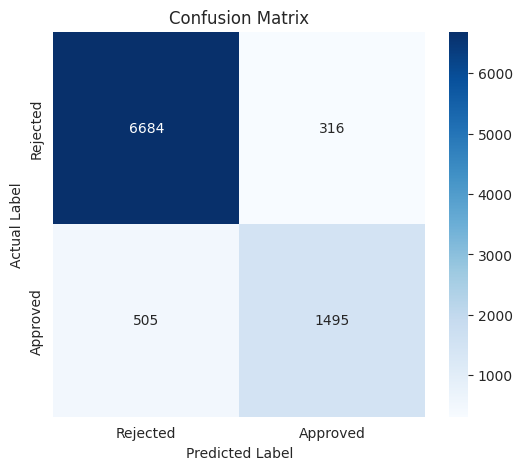

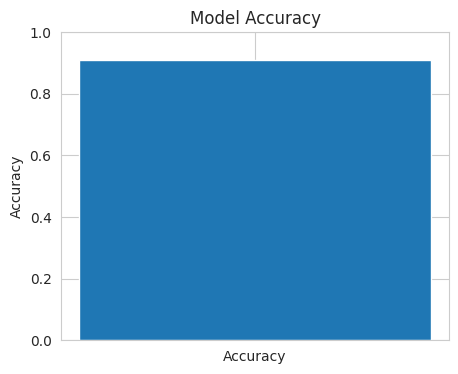

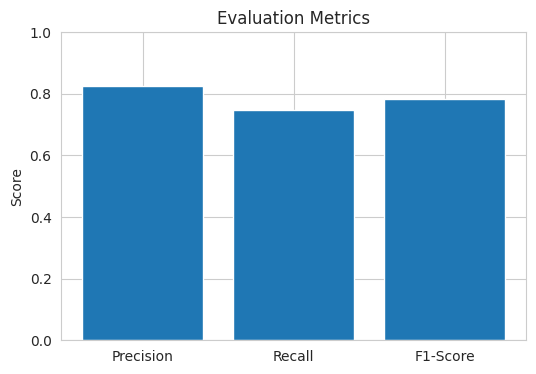

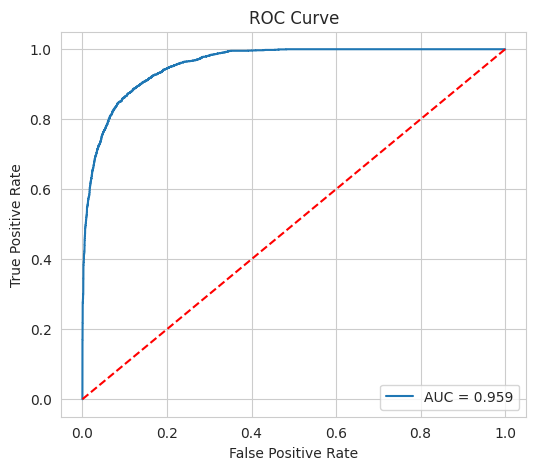

ROC-AUC Score: 0.9586


In [6]:
# ==========================================
# SVM MODEL EVALUATION & VISUALIZATION
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    auc
)

# ==========================
# Evaluation Metrics
# ==========================

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("="*50)
print("SVM Classification Evaluation")
print("="*50)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-Score : {f1:.4f}")

print("\nClassification Report")
print(classification_report(y_test, y_pred))

# ==========================
# Confusion Matrix
# ==========================

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=['Rejected','Approved'],
            yticklabels=['Rejected','Approved'])

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

# ==========================
# Accuracy Bar Chart
# ==========================

plt.figure(figsize=(5,4))
plt.bar(["Accuracy"], [accuracy])
plt.ylim(0,1)
plt.title("Model Accuracy")
plt.ylabel("Accuracy")
plt.show()

# ==========================
# Precision, Recall & F1
# ==========================

metrics = [precision, recall, f1]
labels = ["Precision","Recall","F1-Score"]

plt.figure(figsize=(6,4))
plt.bar(labels, metrics)
plt.ylim(0,1)
plt.title("Evaluation Metrics")
plt.ylabel("Score")
plt.show()

# ==========================
# ROC Curve
# ==========================

y_score = svm_model.decision_function(X_test)

fpr, tpr, thresholds = roc_curve(y_test, y_score)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
plt.plot([0,1],[0,1],'r--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

print(f"ROC-AUC Score: {roc_auc:.4f}")